475
Cells between circles:
Center to r=0.07: 7
r=0.07 to r=0.14: 30
r=0.14 to r=0.21: 48
r=0.21 to r=0.28: 66
r=0.28 to r=0.35: 90
r=0.35 to r=0.42: 108
r=0.42 to r=0.49: 126
r=0.49 to r=0.00: 0


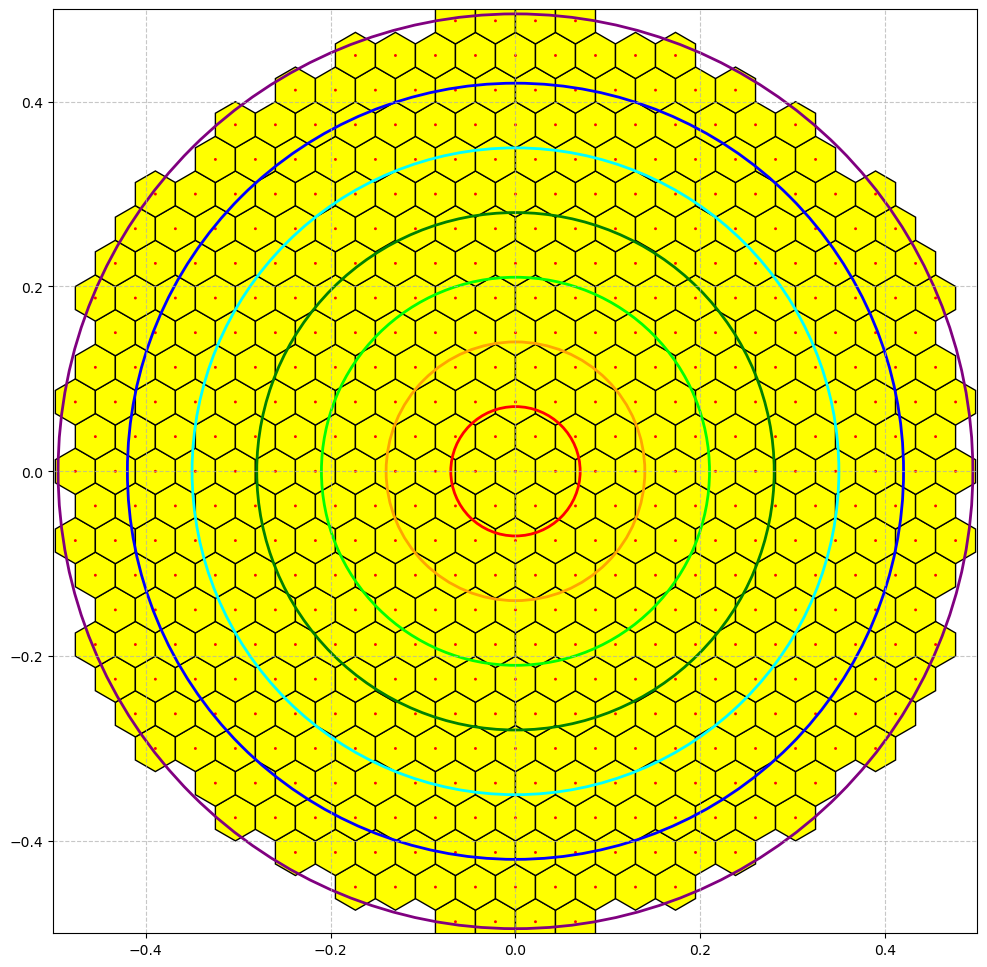

In [1]:
import numpy as np
from scipy import integrate, special
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon, Circle
import pandas as pd


def is_within_circle(x, y, radius):
    """Check if a point (x, y) is within a circle of given radius."""
    return x**2 + y**2 <= radius**2

def is_within_hexagonal_layers(row, col, layers):
    """Check if a hexagon is within the specified number of layers."""
    return abs(row) + abs(col) + abs(-row-col) <= 2 * layers

def hexagon_center(row, col, size):
    """Calculate the center coordinates of a hexagon."""
    x = (col * np.sqrt(3) + row * np.sqrt(3)/2) * size
    y = row * 1.5 * size
    return x, y

def create_honeycomb(size, layers, ax, circle_radii):
    """Create a honeycomb pattern within circular boundaries."""
    cells = {r: 0 for r in circle_radii}
    cells[0] = 0  # Count cells from the center
    count = 0
    for row in range(-layers, layers + 1):
        for col in range(-layers, layers + 1):
            if not is_within_hexagonal_layers(row, col, layers):
                continue
            
            x, y = hexagon_center(row, col, size)
            
            for i, radius in enumerate(circle_radii):
                if is_within_circle(x, y, radius):
                    if i == 0:
                        cells[radius] += 1
                        
                    else:
                        cells[radius] += 1
                        
                    hexagon = RegularPolygon((x, y), numVertices=6, radius=size, 
                                             orientation=0, facecolor='yellow', 
                                             edgecolor='black')
                    ax.add_patch(hexagon)
                    count += 1
                    
                    dot = Circle((x, y), radius=size/16, facecolor='red')
                    ax.add_patch(dot)
                    break

    print(count)
    return cells

def setup_plot(ax, limit=0.5):
    """Set up the plot with proper limits, aspect ratio, and grid."""
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect('equal')
    ax.grid(True, linestyle='--', alpha=0.7)

def add_circular_boundaries(ax, radii, colors):
    """Add circular boundaries to the plot."""
    for radius, color in zip(radii, colors):
        ax.add_patch(Circle((0, 0), radius=radius, fill=False, 
                            edgecolor=color, linewidth=2))

def main():
    # Configuration
    hexagon_size = 0.025
    num_layers = 13
    circle_radii = [0.07, 0.14, 0.21, 0.28, 0.35, 0.42, 0.495]
    colors = ['red', 'orange', 'lime', 'green', 'cyan', 'blue', 'purple']

    # Create figure and axis
    fig, ax = plt.subplots(figsize=(12, 12))

    # Create honeycomb pattern and count cells
    cells = create_honeycomb(hexagon_size, num_layers, ax, circle_radii)

    # Add circular boundaries
    add_circular_boundaries(ax, circle_radii, colors)

    # Setup plot
    setup_plot(ax)

    # Print cell counts
    print("Cells between circles:")
    for i, (radius, count) in enumerate(cells.items()):
        if i == 0:
            print(f"Center to r={radius:.2f}: {count}")
        else:
            print(f"r={circle_radii[i-1]:.2f} to r={radius:.2f}: {count}")

    plt.show()

if __name__ == "__main__":
    main()

# 1. Import pustaka dan mendefinisikan fungsi

In [2]:
def average_bessel_in_ring(r_inner, r_outer, R, dr):
    """
    Calculate the average Bessel function value in a ring.
    Menghitung nilai rata-rata fungsi Bessel dalam ring. 
    """
    def integrand(r):
        return r * special.j0(2.405 * r / (R + dr))
    
    integral, error = integrate.quad(integrand, r_inner, r_outer)
    ring_area = np.pi * (r_outer**2 - r_inner**2)
    return integral * 2 * np.pi / ring_area

def create_default_q_vol(H, d, r_inner, r_outer, R, dr, num_points=1000, q_max=500e6):
    """
    Create a default heat flux distribution using a cosine function with buffer zones,
    adjusted by the average Bessel function for the ring.

    Membuat distribusi pembangkitan kalor volumetric
    """
    z = np.linspace(-H/2, H/2, num_points)
    q_axial = q_max * np.cos(np.pi * z / (H + 2*d))
    q_radial = average_bessel_in_ring(r_inner, r_outer, R, dr)
    q = q_axial * q_radial
    return pd.DataFrame({'z': z, 'q_vol': q})

def load_q_vol(filename=None, H=1.0, d=0.1, r_inner=0, r_outer=0.1, R=1, dr=0.1, num_points=1000):
    """
    Load q_vol data from a CSV file or create a default distribution.
    Returns an interpolation function.

    Mengambil data dari file CSV atau buat sendiri
    """
    if filename:
        try:
            data = pd.read_csv(filename)
        except FileNotFoundError:
            print(f"File {filename} not found. Using default distribution.")
            data = create_default_q_vol(H, d, r_inner, r_outer, R, dr, num_points)
    else:
        data = create_default_q_vol(H, d, r_inner, r_outer, R, dr, num_points)
    
    return interp1d(data['z'], data['q_vol'], kind='linear', fill_value='extrapolate'), data

def dm_dz(z, q_func, fuel_area, latent_heat):
    """
    Differential equation for mass flow rate.
    """
    return fuel_area * q_func(z) / latent_heat

def calculate_mass_flow(z_start, z_end, q_func, fuel_area, latent_heat):
    """
    Calculate the mass flow rate from z_start to z_end using Simpson's rule.
    """
    integrand = lambda z: dm_dz(z, q_func, fuel_area, latent_heat)
    result, error = integrate.quad(integrand, z_start, z_end, epsabs=1e-7, epsrel=1e-7, limit=100)
    return result

# 2. Parameter

In [3]:
# Parameters
filename = None  # Set to None to use default distribution
Height = 1.0  # m, length of the heat pipe
dz = 0.1  # m, buffer zone length
Radius = 0.5  # m, radius of the reactor
dr = 0.1  # m, radial buffer zone
num_rings = 7  # number of rings to divide the reactor
num_cells = [7, 30, 48, 66, 90, 108, 126] # number of cells in each ring
print(np.sum(num_cells))
# Calculate ring boundaries
ring_boundaries = np.linspace(0.000, Radius, num_rings + 1)
ring_midpoints = (ring_boundaries[:-1] + ring_boundaries[1:]) / 2

# Other parameters
fuel_area = 15e-4  # m^2, converted from 15 cm^2
latent_heat = 3827000  # J/kg, latent heat of vaporization

print(ring_boundaries)
print(ring_midpoints)

475
[0.         0.07142857 0.14285714 0.21428571 0.28571429 0.35714286
 0.42857143 0.5       ]
[0.03571429 0.10714286 0.17857143 0.25       0.32142857 0.39285714
 0.46428571]


# 3. Perhitungan untuk tiap ring

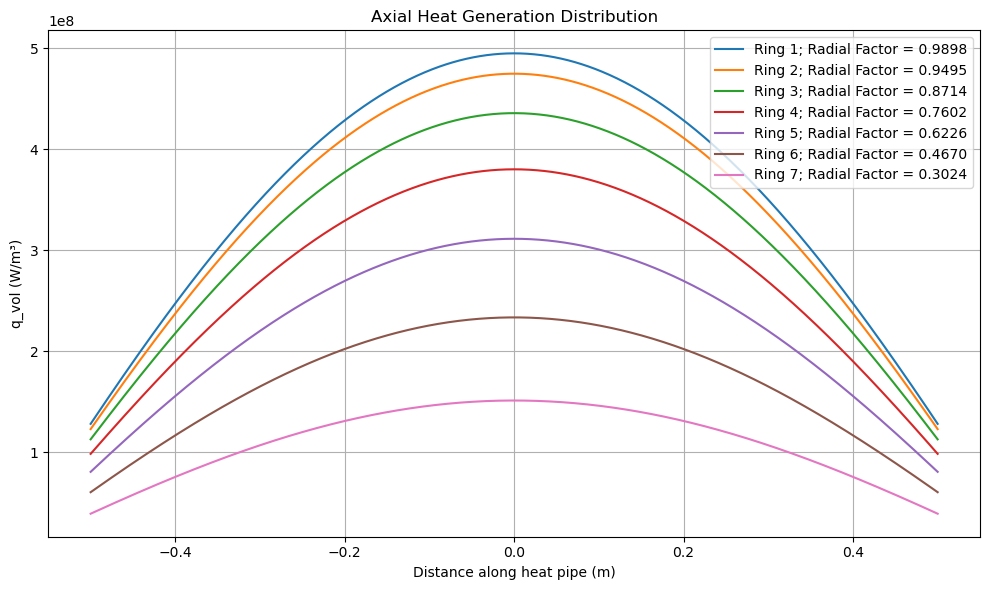

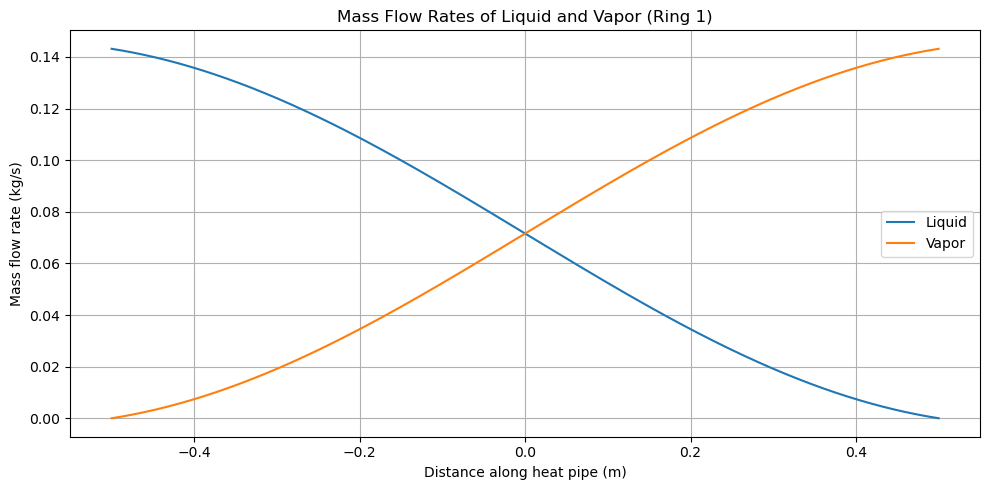


Results for Ring 1 (r_inner = 0.00 m; r_mid = 0.04 m; r_outer = 0.07 m):
Average relative heat flux in this ring: 0.9898
Number of cells in this ring: 7

Total evaporation along the heat pipe: 0.143136 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.143136 kg/s
Average evaporation flux: 95.42 kg/(m^2·s)

Total evaporation in this ring: 1.0020 kg/s (7)*(0.1431)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


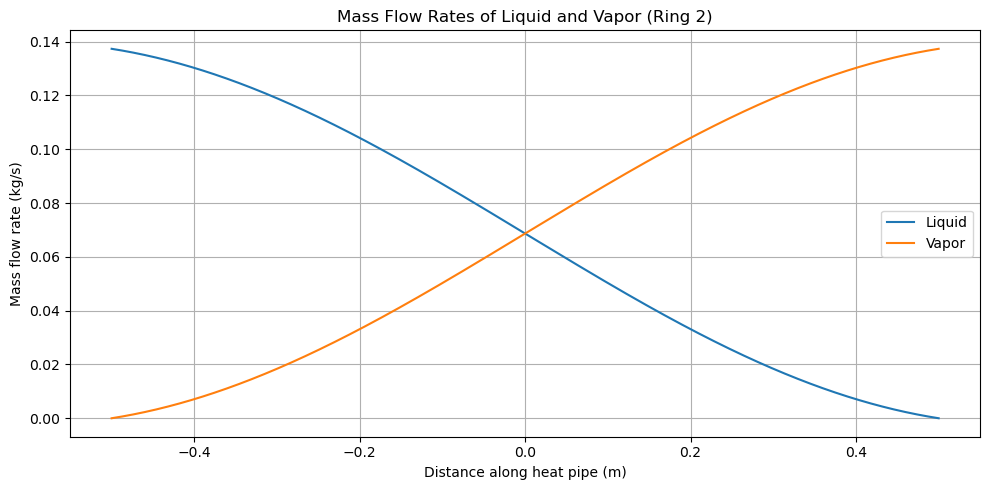


Results for Ring 2 (r_inner = 0.07 m; r_mid = 0.11 m; r_outer = 0.14 m):
Average relative heat flux in this ring: 0.9495
Number of cells in this ring: 30

Total evaporation along the heat pipe: 0.137310 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.137310 kg/s
Average evaporation flux: 91.54 kg/(m^2·s)

Total evaporation in this ring: 4.1193 kg/s (30)*(0.1373)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


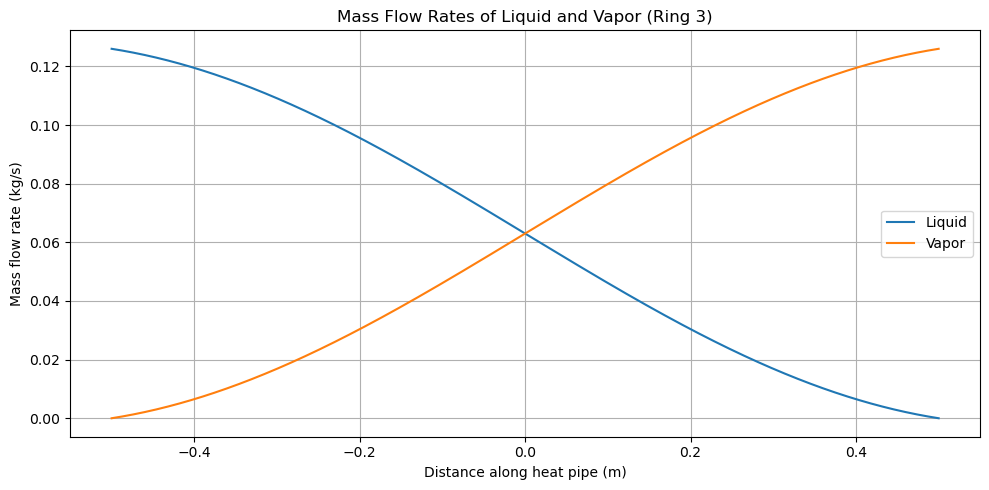


Results for Ring 3 (r_inner = 0.14 m; r_mid = 0.18 m; r_outer = 0.21 m):
Average relative heat flux in this ring: 0.8714
Number of cells in this ring: 48

Total evaporation along the heat pipe: 0.126012 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.126012 kg/s
Average evaporation flux: 84.01 kg/(m^2·s)

Total evaporation in this ring: 6.0486 kg/s (48)*(0.1260)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


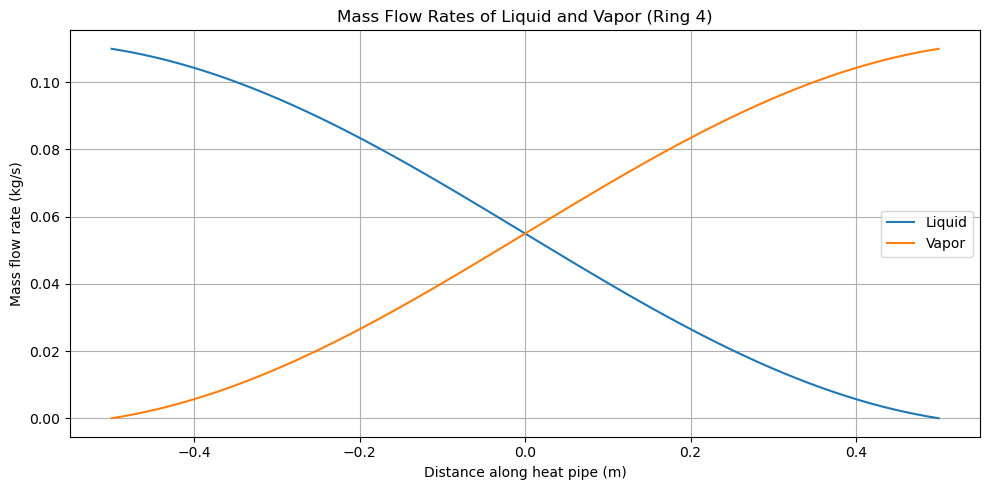


Results for Ring 4 (r_inner = 0.21 m; r_mid = 0.25 m; r_outer = 0.29 m):
Average relative heat flux in this ring: 0.7602
Number of cells in this ring: 66

Total evaporation along the heat pipe: 0.109931 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.109931 kg/s
Average evaporation flux: 73.29 kg/(m^2·s)

Total evaporation in this ring: 7.2554 kg/s (66)*(0.1099)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


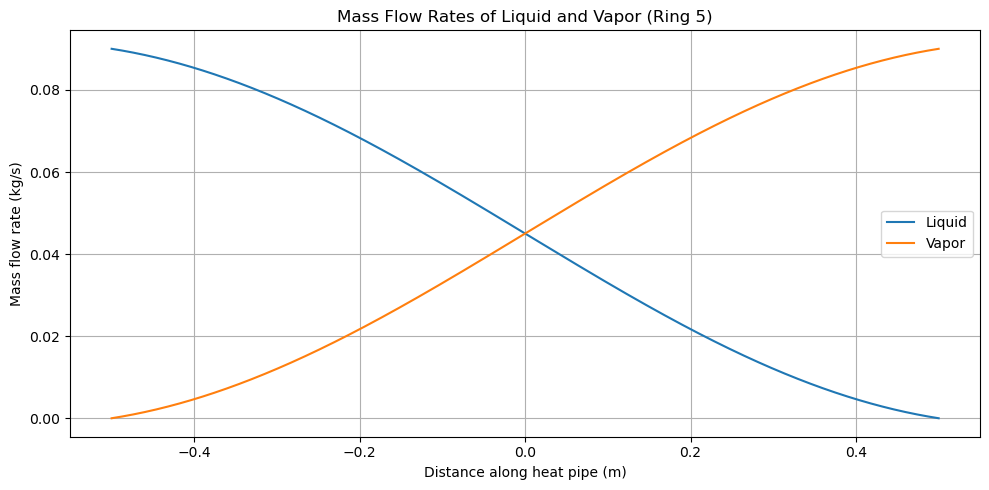


Results for Ring 5 (r_inner = 0.29 m; r_mid = 0.32 m; r_outer = 0.36 m):
Average relative heat flux in this ring: 0.6226
Number of cells in this ring: 90

Total evaporation along the heat pipe: 0.090039 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.090039 kg/s
Average evaporation flux: 60.03 kg/(m^2·s)

Total evaporation in this ring: 8.1035 kg/s (90)*(0.0900)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


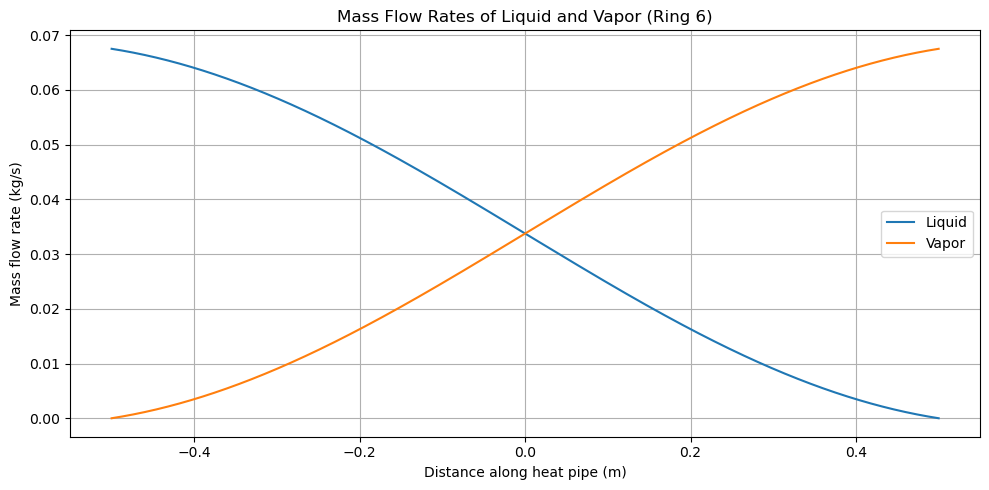


Results for Ring 6 (r_inner = 0.36 m; r_mid = 0.39 m; r_outer = 0.43 m):
Average relative heat flux in this ring: 0.4670
Number of cells in this ring: 108

Total evaporation along the heat pipe: 0.067528 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.067528 kg/s
Average evaporation flux: 45.02 kg/(m^2·s)

Total evaporation in this ring: 7.2930 kg/s (108)*(0.0675)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


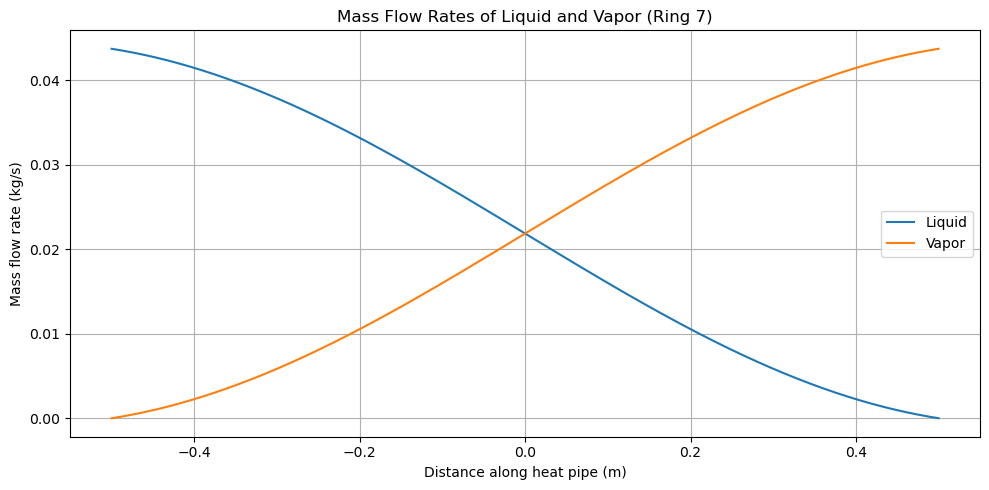


Results for Ring 7 (r_inner = 0.43 m; r_mid = 0.46 m; r_outer = 0.50 m):
Average relative heat flux in this ring: 0.3024
Number of cells in this ring: 126

Total evaporation along the heat pipe: 0.043729 kg/s
Final liquid mass flow rate: 0.000000 kg/s
Final vapor mass flow rate: 0.043729 kg/s
Average evaporation flux: 29.15 kg/(m^2·s)

Total evaporation in this ring: 5.5099 kg/s (126)*(0.0437)
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
[0.14313637458766612, 0.13730967859765475, 0.12601207045885326, 0.10993097949854758, 0.09003892338429852, 0.0675278453185308, 0.04372900967818967]


In [4]:
# Create a single figure for all rings
fig, ax = plt.subplots(figsize=(10, 6))

# Calculate and plot for each ring
for i in range(num_rings):
    r_inner, r_outer = ring_boundaries[i], ring_boundaries[i+1]
    r_mid = ring_midpoints[i]
    bessel_factor = average_bessel_in_ring(r_inner, r_outer, Radius, dr)
    
    # Load q_vol data or create default
    q_func, data = load_q_vol(filename, Height, dz, r_inner, r_outer, Radius, dr)
    
    # Plot heat flux distribution for this ring
    ax.plot(data['z'], data['q_vol'], label=f'Ring {i+1}; Radial Factor = {bessel_factor:.4f}')

# Set up the plot
ax.set_title('Axial Heat Generation Distribution')
ax.set_xlabel('Distance along heat pipe (m)')
ax.set_ylabel('q_vol (W/m³)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()
final_flow = []
liquid_list = []
vapor_list = []

for i in range(num_rings):
    r_inner, r_outer = ring_boundaries[i], ring_boundaries[i+1]
    r_mid = ring_midpoints[i]
    
    # Load q_vol data or create default
    q_func, data = load_q_vol(filename, Height, dz, r_inner, r_outer, Radius, dr)
    
    # Create array of z values
    num_points = 1000
    z_values = np.linspace(-Height/2, Height/2, num_points)
    
    # Calculate evaporation rates and mass flows
    evaporation_rates = [dm_dz(z, q_func, fuel_area, latent_heat) for z in z_values]
    cumulative_evaporation = [calculate_mass_flow(-Height/2, z, q_func, fuel_area, latent_heat) for z in z_values]
    initial_liquid_flow = cumulative_evaporation[-1]
    initial_vapor_flow = 0
    liquid_mass_flow = [initial_liquid_flow - evap for evap in cumulative_evaporation]
    vapor_mass_flow = [initial_vapor_flow + evap for evap in cumulative_evaporation]
    liquid_list.append(liquid_mass_flow)
    vapor_list.append(vapor_mass_flow)
    total_mass_flow = [liquid + vapor for liquid, vapor in zip(liquid_mass_flow, vapor_mass_flow)]
    
    # Plot mass flow rates
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.plot(z_values, liquid_mass_flow, label='Liquid')
    ax1.plot(z_values, vapor_mass_flow, label='Vapor')
    ax1.set_title(f'Mass Flow Rates of Liquid and Vapor (Ring {i+1})')
    ax1.set_xlabel('Distance along heat pipe (m)')
    ax1.set_ylabel('Mass flow rate (kg/s)')
    ax1.grid(True)
    ax1.legend()
    plt.tight_layout()
    plt.show()
    
    # Print results for this ring
    print(f"\nResults for Ring {i+1} (r_inner = {r_inner:.2f} m; r_mid = {r_mid:.2f} m; r_outer = {r_outer:.2f} m):")
    print(f"Average relative heat flux in this ring: {average_bessel_in_ring(r_inner, r_outer, Radius, dr):.4f}")
    print(f"Number of cells in this ring: {num_cells[i]}")
    total_evaporation = cumulative_evaporation[-1]
    final_liquid_flow = liquid_mass_flow[-1]
    final_vapor_flow = vapor_mass_flow[-1]
    final_flow.append(final_vapor_flow)
    final_total_flow = total_mass_flow[-1]
    average_mass_flux = total_evaporation / fuel_area
    print(f"\nTotal evaporation along the heat pipe: {total_evaporation:.6f} kg/s")
    print(f"Final liquid mass flow rate: {final_liquid_flow:.6f} kg/s")
    print(f"Final vapor mass flow rate: {final_vapor_flow:.6f} kg/s")
    print(f"Average evaporation flux: {average_mass_flux:.2f} kg/(m^2·s)")
    print(f"\nTotal evaporation in this ring: {num_cells[i]*total_evaporation:.4f} kg/s ({num_cells[i]})*({total_evaporation:.4f})")
    print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

print(final_flow)

# Calculating Pressure Drop (Vapor)

Elevation Pressure Drop

$$-\frac{dp_{elevation}}{dz}=\rho_v g \cos(\beta)$$

- $\rho_v$ densitas vapor (kg/m3)
- $g$ akselerasi gravitasi (m/s2)
- $\cos{\beta}$ kemiringan pipa (tegak lurus = 1)

Friction Pressure Drop

$$-\frac{dp_{friction}}{dz}=\frac{f_v}{d_v}\frac{m_v^2}{2\rho_v A_v^2}$$

$$A_v = \frac{\pi}{4}d_v^2$$

$$-\frac{dp_{friction}}{dz}=\frac{f_v}{d_v}\frac{m_v^2}{2\rho_v (\frac{\pi}{4}d_v^2)^2}=\frac{8f_v m_v^2}{\pi^2 \rho_v d_v^5}$$

- $m_v$ laju vapor (kg/s)
- $f_v$ faktor friksi
- $d_v$ diameter kanal fase vapor

Acceleration Pressure Drop

$$-\frac{dp_{acceleration}}{dz}=\frac{16}{\pi^2d_v^4}\frac{d}{dz}\frac{m_v^2}{\rho_v}$$

## Solution

Elevation

$$-\Delta{}p_{elevation} = \rho_v g L_H \cos(\beta)$$

### Laminar Flow Friction

$$ -\frac{dp_{friction}}{dz}=\frac{128\mu_v m_v}{\pi \rho_v d_v^4}$$

$$ -\Delta{}p_{friction} = \frac{64\mu_v}{\pi{}\rho_v d_v^4}\frac{Q L_h}{h_{fg}}$$

### Turbulent Flow Friction

$$ -\frac{dp_{friction}}{dz}=\frac{1.472\mu_v^{0.2}m_v^{1.8}}{\pi^{1.8}\rho_v d_v^{4.8}}$$

$$ -\Delta{}p_{friction} = \frac{0.5257 \mu_v^{0.2}}{\rho_v d_v^{4.8}}\left(\frac{Q}{\pi h_{fg}}\right)^{1.8} L_H$$

Acceleration

$$ -\Delta{}p_{acceleration} = \frac{16}{\pi^2 d_v^4 \rho_v } \left(\frac{Q}{h_{fg}}\right)^{2}$$

# Calculating Pressure Drop (Liquid)

Elevation

$$-\Delta{}p_{elevation} = \rho_l g L_H \cos(\beta)$$

Friction

Typical values from literature:
- For sintered wicks: a ≈ 150-180?, b ≈ 1.0
- For wire mesh: a ≈ 120-140, b ≈ 0.85-1.0
- Values vary significantly based on specific wick properties

$$-\Delta{}p_{friction} = \frac{8a}{(3-b)\rho_l d_p^{1+b}}\left(\frac{4}{\mu_l}\right)^{-b}\left(\frac{Q}{\varepsilon \pi (d_i^2 - d_v^2) h_{fg}}\right)^{2-b} L_H$$

$d_p$ diameter of wick pore

$\varepsilon$ porosity of wick

Acceleration

$$ -\Delta{}p_{acceleration} = \frac{16}{\pi^2 \varepsilon^2 (d_i^2 - d_v^2)^2 \rho_l} \left(\frac{Q}{h_{fg}}\right)^{2}$$

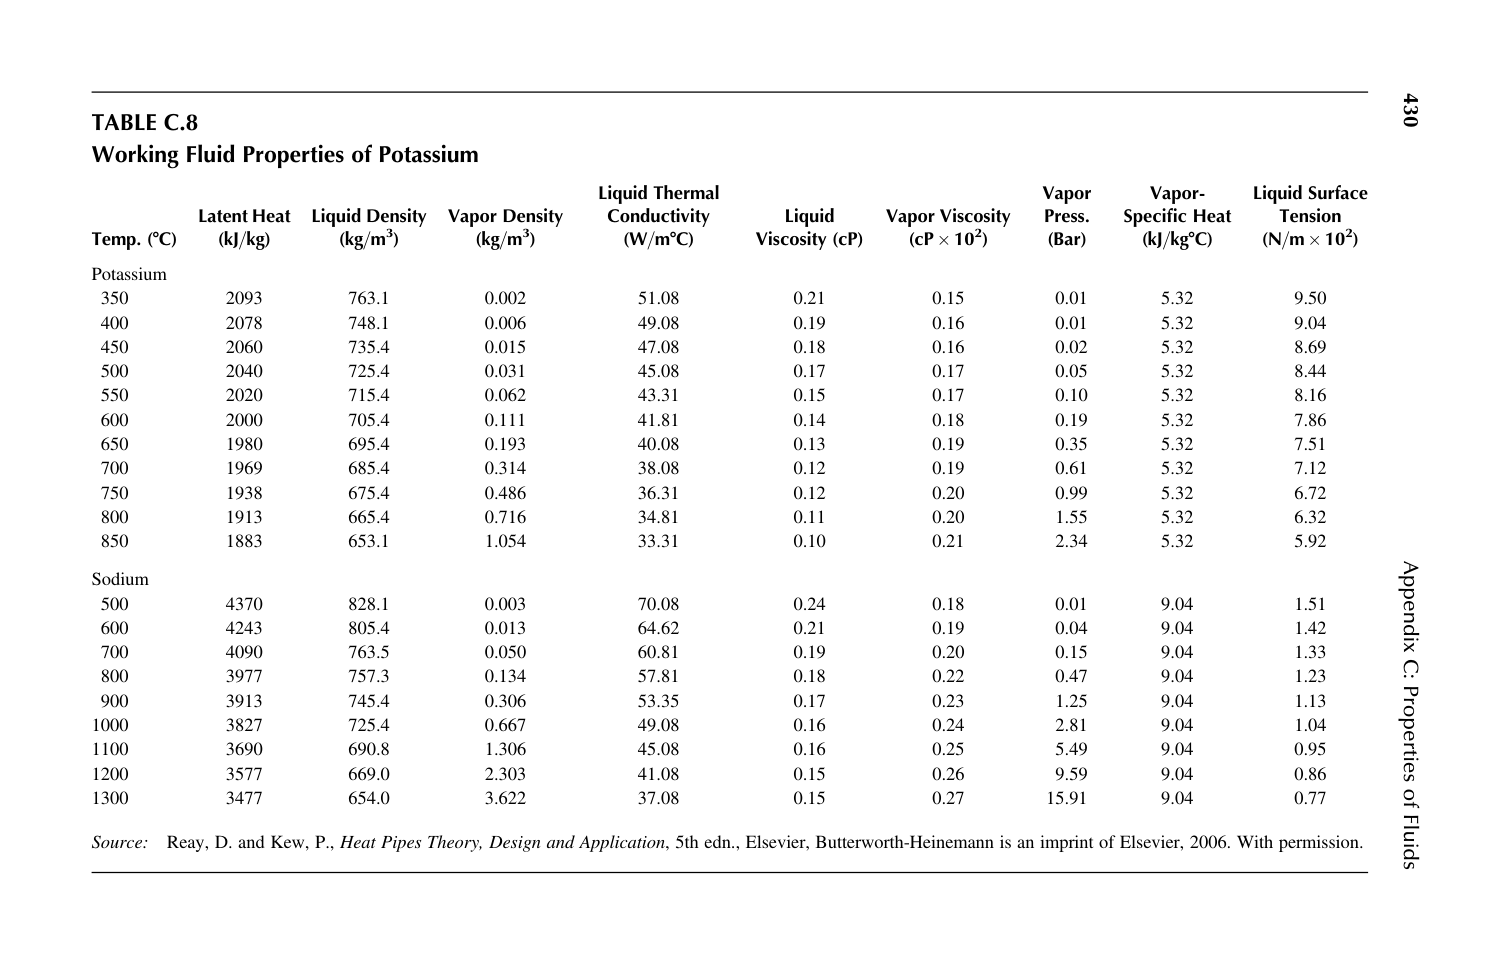

6.54103555 Pascal
7113.743909999999 Pascal
33.73122374509038 Pascal
11166.058753406134 Pascal
1215.7225755386391 Pascal
-9.813754958636583 Pascal


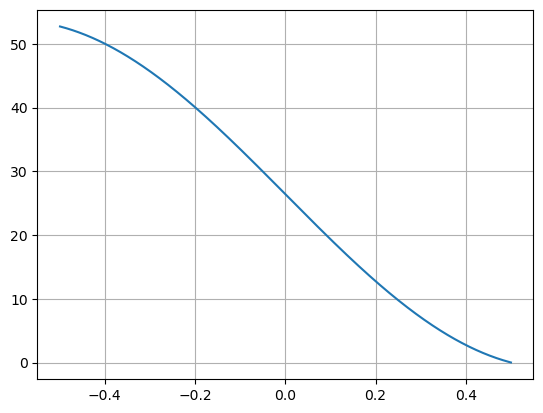

In [68]:
# Constants
from scipy.constants import g, pi

beta = 0
pressure = 101325 # Pascal
temperature = 273 + 1000 # Kelvin
rho_l = 725.4 # kg/m3
rho_v = 0.667 # kg/m3
mu_l = 0.00016 # Pa.s
mu_v = 0.0000024 # Pa.s
d_l = 2 * 0.05 # meter 
d_v = 2 * 0.04 # meter
L_H = 1.0 # meter
h_fg = latent_heat
porosity = 0.6
wick_pore_diameter = 100e-6 # meter 

number_of_points = 1000
z_values = np.linspace(-L_H/2, L_H/2, number_of_points)
z_values = z_values[1:]


liquid_ring1 = np.array(liquid_list[0])
vapor_ring1 = np.array(vapor_list[0])
liquid_ring1 = liquid_ring1[liquid_ring1 != 0]
vapor_ring1 = vapor_ring1[vapor_ring1 != 0]

reynolds_liquid = 4*liquid_ring1*wick_pore_diameter/(mu_l*porosity*pi*(d_l**2 - d_v**2))
reynolds_liquid = reynolds_liquid[reynolds_liquid != 0]
reynolds_vapor = 4*vapor_ring1/(pi*mu_v*d_v)
reynolds_vapor = reynolds_vapor[reynolds_vapor != 0]

def vapor_elevation_drop(rho_v, g, L_H, beta):
    return rho_v * g * L_H * np.cos(beta)

def liquid_elevation_drop(rho_l, g, L_H, beta):
    return rho_l * g * L_H * np.cos(beta)

def vapor_friction_factor_L(Re_v): # Laminar
    return 64/Re_v

def vapor_friction_factor_T(Re_v): # Turbulent
    return 0.184/Re_v**0.2

def liquid_drag_coefficient(Re_l, a, b): # For Re Laminar use a = 24 and b = 1
    return a*Re_l**(-b) 

def vapor_friction_drop(rho_v, d_v, friction, m_v):
    return 8*friction*m_v**2 / (pi**2 * rho_v * d_v**5)

def liquid_friction_drop(rho_l, d_l, d_v, d_p, epsilon, C_l, m_l):
    return C_l/d_p * 8*m_l**2/(pi**2 * rho_l * epsilon**2 * (d_l**2 - d_v**2)**2)

def vapor_acceleration_drop(rho_v, d_v, m_v):
    return 16*m_v**2/(pi**2 * d_v**4 * rho_v)

def liquid_acceleration_drop(rho_l, d_l, d_v, epsilon, m_l):
    return -16*m_l**2/(pi**2 * epsilon**2 * (d_l**2 - d_v**2)**2 * rho_l)

pve = vapor_elevation_drop(rho_v, g, L_H, beta)
ple = liquid_elevation_drop(rho_l, g, L_H, beta)

friction_factor = vapor_friction_factor_T(reynolds_vapor)
dvfdz = vapor_friction_drop(rho_v, d_v, friction_factor, vapor_ring1)
pvf = integrate.simpson(y=dvfdz, x=z_values)

drag = liquid_drag_coefficient(reynolds_liquid, 24, 1)
dlfdz = liquid_friction_drop(rho_l, d_l, d_v, wick_pore_diameter, porosity, drag, liquid_ring1)
plf = integrate.simpson(y=dlfdz, x=z_values)

pva = vapor_acceleration_drop(rho_v, d_v, vapor_ring1[-1])
pla = liquid_acceleration_drop(rho_l, d_l, d_v, porosity, liquid_ring1[0])

print(f'{pve} Pascal')
print(f'{ple} Pascal')
print(f"{pvf} Pascal")
print(f"{plf} Pascal")
print(f"{pva} Pascal")
print(f"{pla} Pascal")

plt.plot(z_values, reynolds_liquid)
plt.grid()
plt.show()

Vapor elevation drop: 6.54 Pascal
Liquid elevation drop: 7113.74 Pascal


C:\Users\Okirain\AppData\Local\Temp\ipykernel_25212\1144466860.py:47: RuntimeWarning: divide by zero encountered in divide
  return 0.184/Re_v**0.2
C:\Users\Okirain\AppData\Local\Temp\ipykernel_25212\1144466860.py:50: RuntimeWarning: invalid value encountered in multiply
  return 8 * friction * m_v**2 / (pi**2 * rho_v * d_v**5)


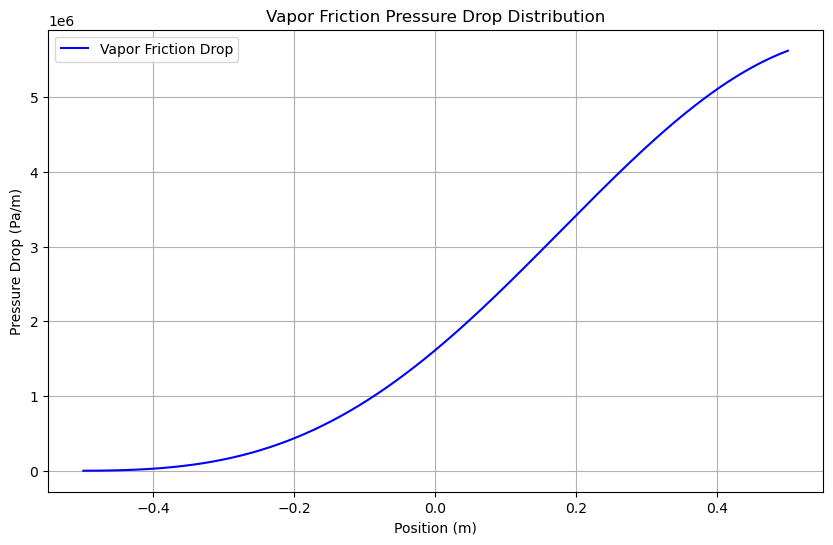

In [14]:
import numpy as np
from scipy.constants import g, pi
from scipy import integrate
import matplotlib.pyplot as plt

# Physical Constants
def define_constants():
    constants = {
        'beta': 0,                    # Angle
        'pressure': 101325,           # Pascal
        'temperature': 273 + 1000,    # Kelvin
        'rho_l': 725.4,              # kg/m3 (liquid density)
        'rho_v': 0.667,              # kg/m3 (vapor density)
        'mu_l': 0.00016,             # Pa.s (liquid viscosity)
        'mu_v': 0.0000024,           # Pa.s (vapor viscosity)
        'd_l': 2 * 0.005,            # meter (liquid diameter)
        'd_v': 2 * 0.004,            # meter (vapor diameter)
        'L_H': 1.0,                  # meter (heat pipe length)
        'h_fg': latent_heat,         # J/kg
        'porosity': 0.6,
        'wick_pore_diameter': 1.8e-6  # meter
    }
    return constants

# Flow Calculations
def calculate_reynolds_numbers(liquid_flow, vapor_flow, constants):
    reynolds_liquid = (4 * liquid_flow * constants['wick_pore_diameter'] /
                      (constants['mu_l'] * constants['porosity'] * pi * 
                       (constants['d_l']**2 - constants['d_v']**2)))
    
    reynolds_vapor = (4 * vapor_flow / 
                     (pi * constants['mu_v'] * constants['d_v']))
    
    return reynolds_liquid, reynolds_vapor

# Pressure Drop Functions
def vapor_elevation_drop(rho_v, g, L_H, beta):
    return rho_v * g * L_H * np.cos(beta)

def liquid_elevation_drop(rho_l, g, L_H, beta):
    return rho_l * g * L_H * np.cos(beta)

def vapor_friction_factor_L(Re_v):  # Laminar
    return 64/Re_v

def vapor_friction_factor_T(Re_v):  # Turbulent
    return 0.184/Re_v**0.2

def vapor_friction_drop(rho_v, d_v, friction, m_v):
    return 8 * friction * m_v**2 / (pi**2 * rho_v * d_v**5)

def main():
    # Initialize constants
    constants = define_constants()
    
    # Setup spatial grid
    number_of_points = 1000
    z_values = np.linspace(-constants['L_H']/2, constants['L_H']/2, number_of_points)
    
    # Convert input lists to numpy arrays
    liquid_ring1 = np.array(liquid_list[0])
    vapor_ring1 = np.array(vapor_list[0])
    
    # Calculate Reynolds numbers
    reynolds_liquid, reynolds_vapor = calculate_reynolds_numbers(
        liquid_ring1, vapor_ring1, constants
    )
    
    # Calculate pressure drops
    v_elevation = vapor_elevation_drop(
        constants['rho_v'], g, constants['L_H'], constants['beta']
    )
    l_elevation = liquid_elevation_drop(
        constants['rho_l'], g, constants['L_H'], constants['beta']
    )
    
    print(f"Vapor elevation drop: {v_elevation:.2f} Pascal")
    print(f"Liquid elevation drop: {l_elevation:.2f} Pascal")
    
    # Calculate friction factors and pressure drop
    friction_factor = vapor_friction_factor_T(reynolds_vapor)
    dvfdz = vapor_friction_drop(
        constants['rho_v'], constants['d_v'], friction_factor, vapor_ring1
    )
    
    # Calculate total pressure drop through integration
    pvf = integrate.simpson(y=dvfdz, x=z_values)
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(z_values, dvfdz, 'b-', label='Vapor Friction Drop')
    plt.xlabel('Position (m)')
    plt.ylabel('Pressure Drop (Pa/m)')
    plt.title('Vapor Friction Pressure Drop Distribution')
    plt.grid(True)
    plt.legend()
    plt.show()

if __name__ == "__main__":
    main()

In [38]:
import numpy as np

def flow_calculations(mass_flow, density, pipe_diameter=None, units='metric'):
    """
    Calculate volumetric flow and velocity from mass flow
    
    Parameters:
    mass_flow: Mass flow rate (kg/s for metric, lb/s for imperial)
    density: Fluid density (kg/m³ for metric, lb/ft³ for imperial)
    pipe_diameter: Pipe diameter (m for metric, ft for imperial)
    units: 'metric' or 'imperial'
    
    Returns:
    Dictionary with flow rates and velocity if pipe diameter is given
    """
    # Calculate volumetric flow
    volumetric_flow = mass_flow / density
    
    # Calculate velocity if pipe diameter is provided
    if pipe_diameter is not None:
        area = np.pi * (pipe_diameter/2)**2  # Cross-sectional area
        velocity = volumetric_flow / area
    else:
        velocity = None
        area = None
    
    if units == 'metric':
        results = {
            'volumetric_flow': {
                'm3_per_second': volumetric_flow,
                'm3_per_hour': volumetric_flow * 3600,
                'liters_per_minute': volumetric_flow * 60000
            }
        }
        
        if velocity is not None:
            results['velocity'] = {
                'meters_per_second': velocity,
                'kilometers_per_hour': velocity * 3.6
            }
            results['pipe_area'] = {
                'square_meters': area
            }
            
        return results
    
    else:  # Imperial units
        results = {
            'volumetric_flow': {
                'ft3_per_second': volumetric_flow,
                'ft3_per_minute': volumetric_flow * 60,  # CFM
                'gallons_per_minute': volumetric_flow * 448.83  # GPM
            }
        }
        
        if velocity is not None:
            results['velocity'] = {
                'feet_per_second': velocity,
                'miles_per_hour': velocity * 0.681818  # Convert ft/s to mph
            }
            results['pipe_area'] = {
                'square_feet': area
            }
            
        return results

# Example usage:
# Metric example
mass_flow = 0.15  # kg/s
water_density = 0.667  # kg/m³
pipe_diameter = 2 * 0.04  # meters

# Calculate with pipe diameter (includes velocity)
result_with_velocity = flow_calculations(
    mass_flow=mass_flow,
    density=water_density,
    pipe_diameter=pipe_diameter,
    units='metric'
)
print("\nMetric Results:")
print(result_with_velocity)

# Imperial example
mass_flow_imperial = 100  # lb/s
water_density_imperial = 62.4  # lb/ft³
pipe_diameter_imperial = 0.656168  # feet (equivalent to 0.2 m)

result_imperial = flow_calculations(
    mass_flow=mass_flow_imperial,
    density=water_density_imperial,
    pipe_diameter=pipe_diameter_imperial,
    units='imperial'
)
print("\nImperial Results:")
print(result_imperial)


Metric Results:
{'volumetric_flow': {'m3_per_second': 0.22488755622188902, 'm3_per_hour': 809.5952023988004, 'liters_per_minute': 13493.253373313342}, 'velocity': {'meters_per_second': 44.7399577657127, 'kilometers_per_hour': 161.06384795656572}, 'pipe_area': {'square_meters': 0.005026548245743669}}

Imperial Results:
{'volumetric_flow': {'ft3_per_second': 1.6025641025641026, 'ft3_per_minute': 96.15384615384616, 'gallons_per_minute': 719.2788461538462}, 'velocity': {'feet_per_second': 4.739095223705618, 'miles_per_hour': 3.2312004272365176}, 'pipe_area': {'square_feet': 0.33815824053246546}}
